#### Creating the model from scratch

#### Importing MNIST dataset

In [ ]:
from tensorflow.keras.datasets import mnist

#### Importing Libraries

In [ ]:
from keras.models import Model
from keras.layers import *

#### Loading the MNIST dataset

In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

#### Data Normalization

In [ ]:
from tensorflow.keras.utils import to_categorical

In [ ]:
x_train = x_train/255
x_test = x_test/255
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

#### Creating Layers

In [ ]:
input_layer = Input(shape=(28,28))

flatten = Flatten(input_shape = (28,28))(input_layer)

hidden1 = Dense(128, activation='relu')(flatten)
hidden2 = Dense(256, activation='relu')(flatten)
hidden11 = Dense(64, activation='relu')(hidden1)

merge = concatenate([hidden11, hidden2])

output_layer = Dense(10, activation='softmax')(merge)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


#### Creating model

In [ ]:
model = Model(
    inputs = input_layer,
    outputs = output_layer
)

#### Model Summary

In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 28, 28)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 784)       │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │    100,480 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │      8,256 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 256)       │    200,960 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 320)       │          0 │ dense_6[0][0],    │
│ (Concatenate)       │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 10)        │      3,210 │ concatenate_1[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 312,906 (1.19 MB)

 Trainable params: 312,906 (1.19 MB)

 Non-trainable params: 0 (0.00 B)

#### Ploting the model architecture

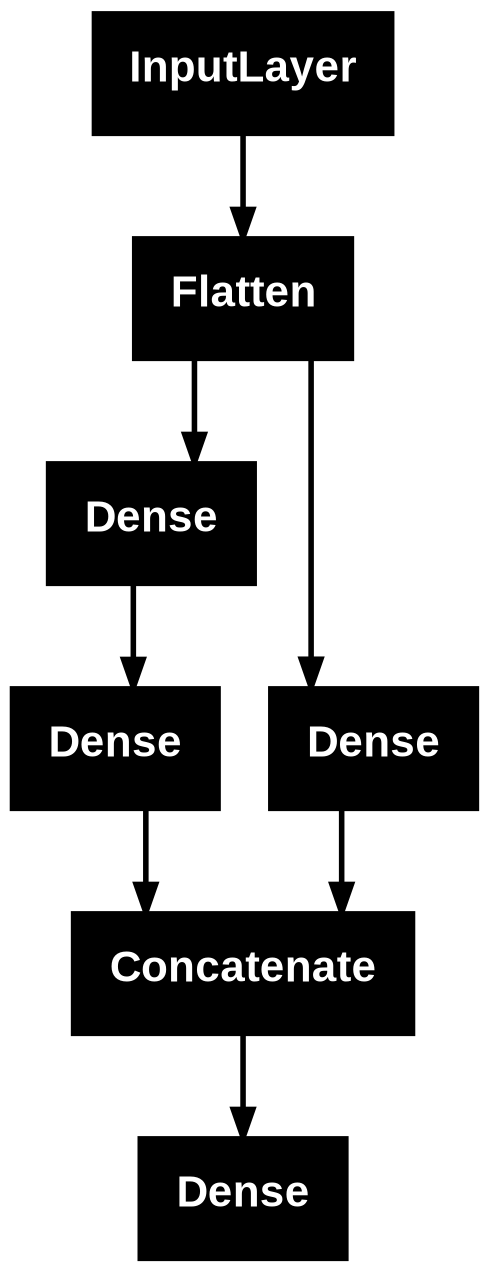

In [ ]:
from keras.utils import plot_model

plot_model(model)

#### Compiling the model


In [ ]:
model.compile(
    optimizer='adam',
    loss = 'categorical_crossentropy',
    metrics=['accuracy']
)

#### Fit the Model

In [ ]:
model.fit(
    x_train, y_train,
    batch_size=32,
    epochs=5,
    verbose=2
)

Epoch 1/5
1875/1875 - 10s - 5ms/step - accuracy: 0.9381 - loss: 0.2091
Epoch 2/5
1875/1875 - 9s - 5ms/step - accuracy: 0.9753 - loss: 0.0826
Epoch 3/5
1875/1875 - 8s - 4ms/step - accuracy: 0.9821 - loss: 0.0543
Epoch 4/5
1875/1875 - 7s - 4ms/step - accuracy: 0.9871 - loss: 0.0400
Epoch 5/5
1875/1875 - 8s - 4ms/step - accuracy: 0.9906 - loss: 0.0287


#### Evaluting the model

In [ ]:
model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9782 - loss: 0.0755


[0.0754697322845459, 0.9782000184059143]

#### Save the model

In [ ]:
model.save('mnist.keras')